3. سوالات تکلیف

3-5 تاثیر تعداد فیلتر ها (عمق کانال) در CNN روی MNIST

در بخش ‌های قبلی، تأثیر اندازه کرنل، استراید، پدینگ و تعداد لایه ‌ها بررسی شد، اما تعداد فیلترها (عمق کانال) ثابت بود. در این آزمایش، اثر تغییر تعداد فیلترهای لایه ‌های کانولوشن را روی دقت، تعداد پارامترها و زمان آموزش بررسی می‌کنیم.

3-5-1 معماری پایه
یک CNN ساده با دو لایه کانولوشن (هر کدام با کرنل ۳×۳، استراید ۱، پدینگ same) و یک لایه پولینگ ۲×۲ بعد از هر لایه کانولوشن، و سپس یک لایه کاملاً متصل با ۱۰ خروجی در نظر بگیرید. تعداد فیلترهای لایه اول و دوم را به صورت جفت (f1, f2) تغییر دهید. سایر پارامترها ثابت می ‌مانند:

•	epochs = 10

•	optimizer = Adam

•	learning rate = 0.001

•	batch size = 64

•	داده: MNIST بدون نویز

•	مقادیر مورد بررسی برای (f1, f2):  (4, 8), (8, 16), (16, 32), (32, 64), (64, 128) 



In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, TensorDataset
import torchvision
from torchvision import transforms, datasets, models
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from datetime import datetime
import os
from pathlib import Path
import sys
import time
from PIL import Image
import requests
from io import BytesIO
import copy


sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_moons_data, get_mnist_data, get_mnist_data_with_noise
from plotting import plot_signals
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

In [2]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_mnist_data(batch_size=64)

In [3]:
class FlexibleCNN(nn.Module):
    def __init__(self, filters1=16, filters2=32, kernel_size=3, input_channels=1, num_classes=10):
        super(FlexibleCNN, self).__init__()
        self.conv1 = nn.Conv2d(input_channels, filters1, kernel_size, stride=1, padding='same')
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)  # 28 -> 14

        self.conv2 = nn.Conv2d(filters1, filters2, kernel_size, stride=1, padding='same')
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)  # 14 -> 7

        self.fc = nn.Linear(filters2 * 7 * 7, num_classes)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [4]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [5]:
def train_and_evaluate(model, train_loader, test_loader, epochs=10, lr=0.001):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_acc_history = []
    test_acc_history = []
    start_time = time.time()

    for epoch in range(epochs):
        # Training phase
        model.train()
        correct_train = 0
        total_train = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
        train_acc = 100 * correct_train / total_train
        train_acc_history.append(train_acc)

        # Evaluation phase
        model.eval()
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()
        test_acc = 100 * correct_test / total_test
        test_acc_history.append(test_acc)

        if (epoch+1) % 5 == 0:
            print(f"Epoch {epoch+1:2d}/{epochs} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

    total_time = time.time() - start_time
    return train_acc_history, test_acc_history, total_time


3-5-2 برای هر پیکربندی، جدول زیر را کامل کنید:

•	تعداد پارامترهای قابل یادگیری

•	دقت نهایی روی مجموعه آزمون

•	زمان کل آموزش (ثانیه)


In [6]:
filter_configs = [
    (4, 8),
    (8, 16),
    (16, 32),
    (32, 64),
    (64, 128)
]

results = []


In [7]:
print("\n===== Experiment: Effect of Number of Filters =====")
for f1, f2 in filter_configs:
    print(f"\n--- Training with filters = ({f1}, {f2}) ---")
    model = FlexibleCNN(filters1=f1, filters2=f2)
    num_params = count_parameters(model)
    print(f"Total trainable parameters: {num_params:,}")

    train_accs, test_accs, train_time = train_and_evaluate(model, train_loader, test_loader, epochs=20, lr=0.001)

    final_test_acc = test_accs[-1]
    results.append({
        'filters': f'({f1},{f2})',
        'f1': f1,
        'f2': f2,
        'params': num_params,
        'final_test_acc': final_test_acc,
        'train_time': train_time,
        'train_acc_history': train_accs,
        'test_acc_history': test_accs,
        'model': model
    })
    print(f"Final test accuracy: {final_test_acc:.2f}% | Training time: {train_time:.2f}s")



===== Experiment: Effect of Number of Filters =====

--- Training with filters = (4, 8) ---
Total trainable parameters: 4,266
Epoch  5/20 | Train Acc: 98.03% | Test Acc: 98.20%
Epoch 10/20 | Train Acc: 98.48% | Test Acc: 98.25%
Epoch 15/20 | Train Acc: 98.75% | Test Acc: 98.22%
Epoch 20/20 | Train Acc: 98.88% | Test Acc: 98.30%
Final test accuracy: 98.30% | Training time: 231.54s

--- Training with filters = (8, 16) ---
Total trainable parameters: 9,098
Epoch  5/20 | Train Acc: 98.80% | Test Acc: 98.53%
Epoch 10/20 | Train Acc: 99.28% | Test Acc: 98.68%
Epoch 15/20 | Train Acc: 99.55% | Test Acc: 98.68%
Epoch 20/20 | Train Acc: 99.68% | Test Acc: 98.68%
Final test accuracy: 98.68% | Training time: 274.82s

--- Training with filters = (16, 32) ---
Total trainable parameters: 20,490
Epoch  5/20 | Train Acc: 99.12% | Test Acc: 98.44%
Epoch 10/20 | Train Acc: 99.56% | Test Acc: 98.97%
Epoch 15/20 | Train Acc: 99.80% | Test Acc: 98.66%
Epoch 20/20 | Train Acc: 99.84% | Test Acc: 98.87%
Fin

In [8]:
df_results = pd.DataFrame([(r['filters'], r['params'], r['final_test_acc'], r['train_time']) for r in results],
                          columns=['Filter Config (f1,f2)', '#Parameters', 'Test Acc (%)', 'Training Time (s)'])
print("\n===== Results Table =====")
print(df_results.to_string(index=False))
df_results.to_csv('filter_experiment_results.csv', index=False)



===== Results Table =====
Filter Config (f1,f2)  #Parameters  Test Acc (%)  Training Time (s)
                (4,8)         4266         98.30         231.536490
               (8,16)         9098         98.68         274.816196
              (16,32)        20490         98.87         291.925878
              (32,64)        50186         98.84         276.095199
             (64,128)       137226         98.92         276.979662


3-5-3 رابطه بین افزایش تعداد فیلترها و دقت نهایی چیست؟ آیا افزایش بیش از حد فیلترها باعث کاهش دقت (overfitting) می‌شود؟ پاسخ خود را با ذکر دلیل توضیح دهید.

3-5-4 نمودار دقت آزمون در طول دوره‌ های آموزش را برای همه پیکربندی‌ ها در یک شکل رسم کنید. همچنین نمودار تعداد پارامترها در مقابل دقت نهایی را رسم کنید.

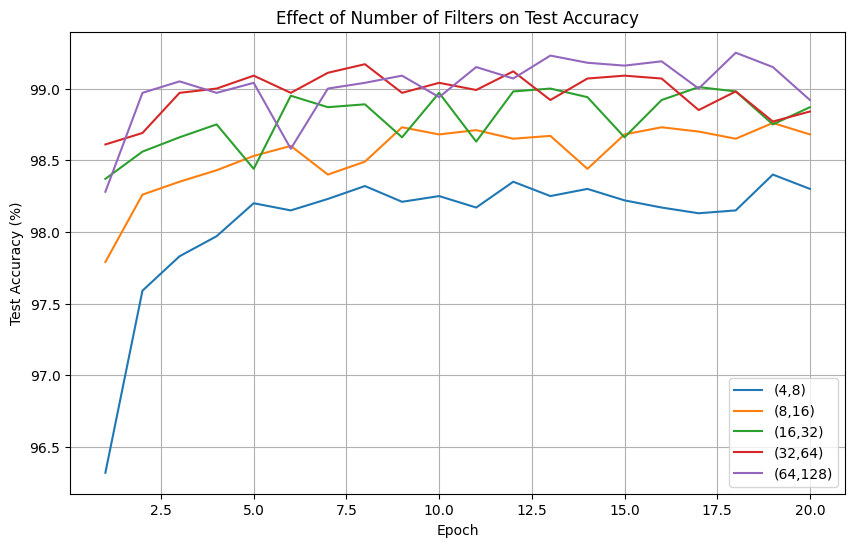

In [10]:
plt.figure(figsize=(10, 6))
for r in results:
    plt.plot(range(1, 21), r['test_acc_history'], label=f"({r['f1']},{r['f2']})")
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Effect of Number of Filters on Test Accuracy')
plt.legend()
plt.grid(True)
plt.savefig('filter_accuracy_curves.png', dpi=150)
plt.show()


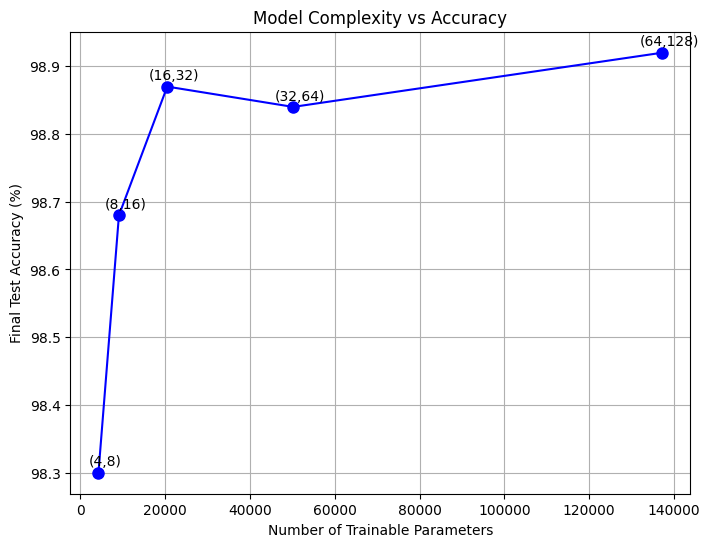

In [11]:
plt.figure(figsize=(8, 6))
params_list = [r['params'] for r in results]
acc_list = [r['final_test_acc'] for r in results]
plt.plot(params_list, acc_list, 'bo-', markersize=8)
for r in results:
    plt.annotate(r['filters'], (r['params'], r['final_test_acc']), textcoords="offset points", xytext=(5,5), ha='center')
plt.xlabel('Number of Trainable Parameters')
plt.ylabel('Final Test Accuracy (%)')
plt.title('Model Complexity vs Accuracy')
plt.grid(True)
plt.savefig('params_vs_accuracy.png', dpi=150)
plt.show()


3-5-5 بهترین پیکربندی از نظر تعادل بین دقت و اندازه مدل (پارامترها) کدام است؟ معیار خود را توضیح دهید.

3-5-6 یکی از تصاویر آزمون را انتخاب کنید و نقشه ویژگی ‌های لایه اول را برای پیکربندی با (4,8)  و (64,128)  نمایش دهید. تفاوت ظاهری نقشه‌ ها را تفسیر کنید.

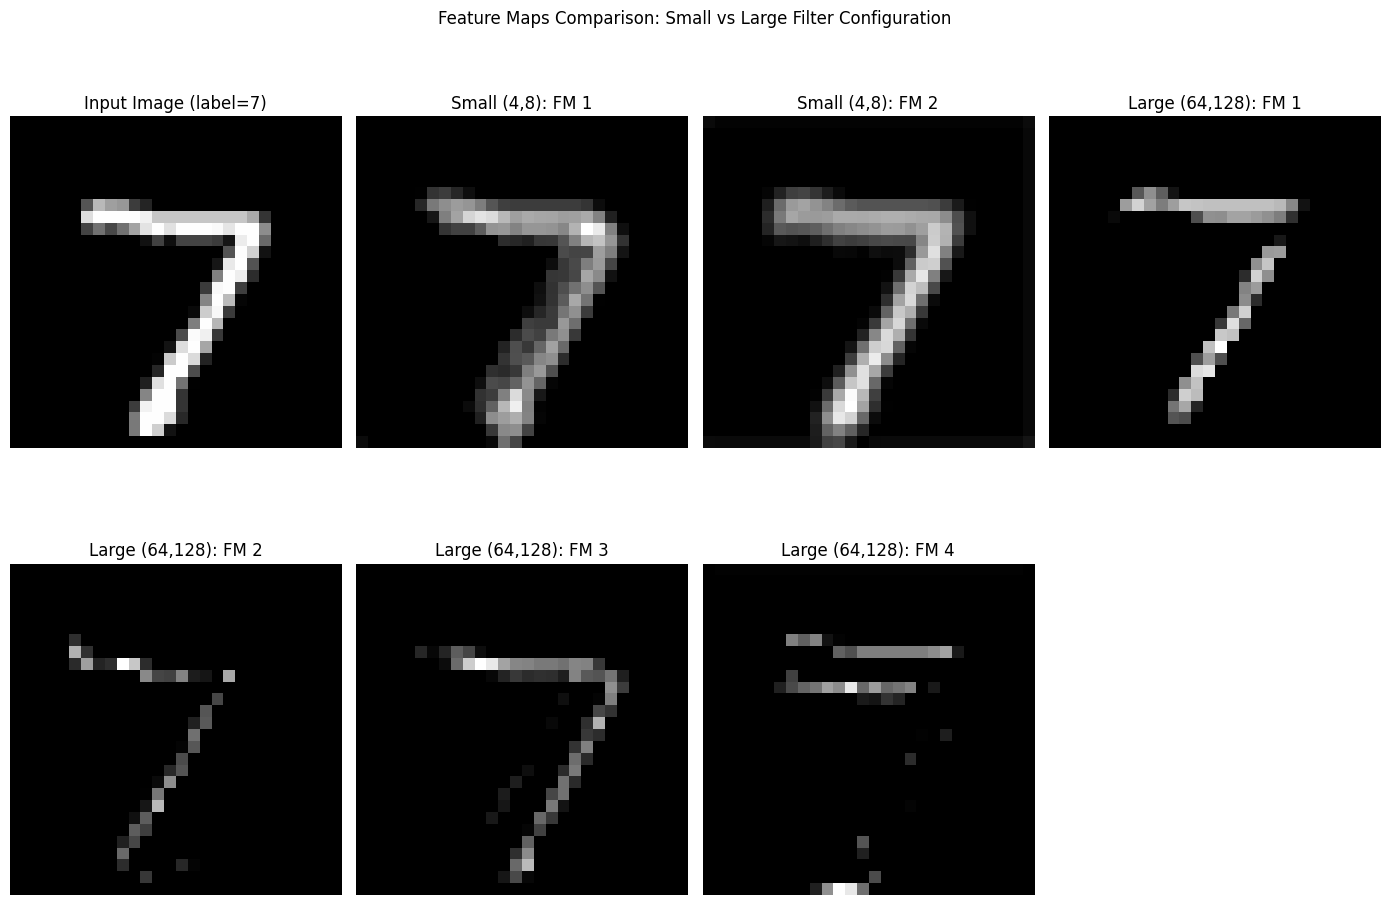

In [13]:
test_iter = iter(test_loader)
test_images, test_labels = next(test_iter)
sample_image = test_images[0:1]  # shape (1,1,28,28)

# Get models for (4,8) and (64,128)
model_small = results[0]['model']  # (4,8)
model_large = results[4]['model']  # (64,128)
model_small.eval()
model_large.eval()

def get_feature_maps(model, input_tensor):
    with torch.no_grad():
        x = model.conv1(input_tensor.to(device))
        x = model.relu1(x)
        return x[0].cpu().numpy()  # shape (filters, H, W)

fm_small = get_feature_maps(model_small, sample_image)  # (4, 28, 28)
fm_large = get_feature_maps(model_large, sample_image)  # (64, 28, 28)

# Display input image
img_display = sample_image[0,0].cpu().numpy()
plt.figure(figsize=(14, 10))

# For small model (4 filters)
plt.subplot(2, 4, 1)
plt.imshow(img_display, cmap='gray')
plt.title(f'Input Image (label={test_labels[0].item()})')
plt.axis('off')

for i in range(min(4, fm_small.shape[0])):
    plt.subplot(2, 4, i+2)
    fm = fm_small[i, :, :]
    fm_norm = (fm - fm.min()) / (fm.max() - fm.min() + 1e-8)
    plt.imshow(fm_norm, cmap='gray')
    plt.title(f'Small (4,8): FM {i+1}')
    plt.axis('off')

# For large model, show first 4 filters
for i in range(4):
    plt.subplot(2, 4, i+4)
    fm = fm_large[i, :, :]
    fm_norm = (fm - fm.min()) / (fm.max() - fm.min() + 1e-8)
    plt.imshow(fm_norm, cmap='gray')
    plt.title(f'Large (64,128): FM {i+1}')
    plt.axis('off')

plt.suptitle('Feature Maps Comparison: Small vs Large Filter Configuration')
plt.tight_layout()
plt.savefig('feature_maps_filter_comparison.png', dpi=150)
plt.show()
